# Bunny ($S^{1} \vee S^{2} \vee S^{1}$)

A wedge of two circles and a sphere. Extends the sphere $\vee$ circle example with two distinct $H^{1}$ generators.

In [2]:
from dreimac import ToroidalCoords
from dreimac.utils import CircleMapUtils

import numpy as np
from scipy.special import softmax
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from torofit.partition_utils import total_variation_scores
import torofit as TF
import cmasher as cmr
%load_ext autoreload
%autoreload 2
color_map_1 = 'hsv'
color_map_2 = 'cmr.seasons_s'
color_maps = [plt.colormaps[color_map_1], plt.colormaps[color_map_2]]
pio.renderers.default = "notebook_connected"
np.random.seed(0)

In [3]:
def generate_s1_s2_s1_point_cloud(n_points=1000, n_circle=500,
                                  sphere_radius=8, circle1_radius=5, circle2_radius=5.1,
                                  wedge_point=None,
                                  circle1_normal=None,
                                  circle2_normal=None,
                                  noise=0.05):
    """
    Generates a point cloud for S^1 ∨ S^2 ∨ S^1 with all three spaces
    wedged at a single point on the sphere.

    Each circle's plane passes through the wedge point and is perpendicular
    to its given normal vector.

    Parameters:
      n_points : int - number of points on the sphere
      n_circle : int - number of points per circle
      sphere_radius : float - radius of the sphere
      circle1_radius, circle2_radius : float - radii of the two circles
      wedge_point : 3D array - point on the sphere where all spaces meet
      circle1_normal : 3D array - normal to circle 1's plane
      circle2_normal : 3D array - normal to circle 2's plane

    Returns:
      point_cloud : (N x 3) numpy array
    """
    # 1. Sphere
    phi = np.random.uniform(0, 2 * np.pi, n_points)
    z = np.random.uniform(-1, 1, n_points)
    r = sphere_radius * np.sqrt(1 - z**2)
    sphere_points = np.column_stack((r * np.cos(phi), r * np.sin(phi), sphere_radius * z))

    # 2. Defaults
    if wedge_point is None:
        wedge_point = np.array([0, 0, sphere_radius])
    if circle1_normal is None:
        circle1_normal = np.array([0, 1, 0])
    if circle2_normal is None:
        circle2_normal = np.array([np.sin(np.pi/4), np.cos(np.pi/4), 0])

    angles = np.linspace(0, 2 * np.pi, n_circle, endpoint=False)

    def make_circle(p0, normal, radius, angles):
        """
        Circle of given radius in the plane through p0 with given normal,
        passing through p0.
        """
        p0 = np.array(p0, dtype=float)
        n = np.array(normal, dtype=float)
        n = n / np.linalg.norm(n)

        # Find two orthonormal vectors in the plane
        # Pick an arbitrary vector not parallel to n
        if abs(np.dot(n, [1, 0, 0])) < 0.9:
            aux = np.array([1, 0, 0])
        else:
            aux = np.array([0, 1, 0])

        e1 = np.cross(n, aux)
        e1 = e1 / np.linalg.norm(e1)
        e2 = np.cross(n, e1)
        e2 = e2 / np.linalg.norm(e2)

        # Center offset so circle passes through p0 at t=π
        center = p0 + radius * e1
        return np.array([
            center + radius * (np.cos(t) * e1 + np.sin(t) * e2)
            for t in angles
        ])

    circle1 = make_circle(wedge_point, circle1_normal, circle1_radius, angles)
    circle2 = make_circle(wedge_point, circle2_normal, circle2_radius, angles)
    point_cloud = np.vstack([sphere_points, circle1, circle2])
    point_cloud += np.random.normal(0, noise, point_cloud.shape)
    return point_cloud, sphere_points, circle1, circle2

# Circle 1 in the xz-plane, circle 2 rotated 45° about z
point_cloud, sphere, circle1, circle2= generate_s1_s2_s1_point_cloud(
    wedge_point=np.array([0, 0, 8]),
    circle1_normal=np.array([0, -1, 1]),      
    circle2_normal=np.array([0, -1, -1]),      
    noise=0.1)
# Visualize using Plotly's go.Figure
fig = go.Figure()

fig.add_trace(go.Scatter3d(
    x=point_cloud[:, 0],
    y=point_cloud[:, 1],
    z=point_cloud[:, 2],
    mode='markers',
    marker=dict(
        size=2,
        color='#ff69b4',
        opacity=0.8
    ),
    name=r'$S^1 \vee S^2 \vee S^1$ (Radial Circles)'
))



fig.update_layout(
    title=r'Point Cloud for $S^1 \vee S^2 \vee S^1$ (Radial Circles)',
    scene=dict(
        xaxis=dict(
            showbackground=False,
            showticklabels=False,
            showgrid=False,
            zeroline=False,
            visible=False
        ),
        yaxis=dict(
            showbackground=False,
            showticklabels=False,
            showgrid=False,
            zeroline=False,
            visible=False
        ),
        zaxis=dict(
            showbackground=False,
            showticklabels=False,
            showgrid=False,
            zeroline=False,
            visible=False
        )
    ),
    paper_bgcolor="white",
    plot_bgcolor="white"
)

fig.update_layout(
    scene=dict(
        aspectmode='manual',    # <— force equal scaling on x,y,z
        xaxis=dict(visible=False),
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
    ),
    margin=dict(l=0,r=0,b=0,t=30),
    paper_bgcolor='white',
)

fig.show()

In [4]:
tc_bunny = ToroidalCoords(point_cloud, n_landmarks=len(point_cloud))
tc_total_theta = tc_bunny.get_coordinates(cocycle_idxs=[0,1])

Coordinate range: 0.0003088247391281601 to 6.2830605971617235


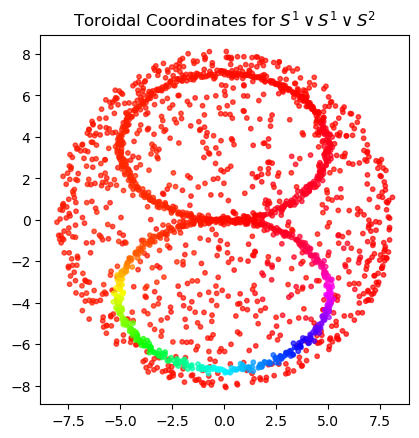

Coordinate range: 0.005770172053883175 to 6.272556187538094


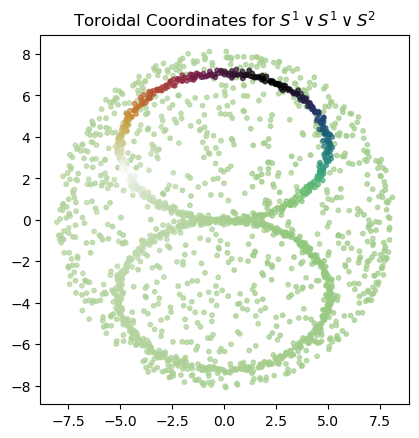

In [4]:
for i, coord in enumerate(tc_total_theta):
    print(f'Coordinate range: {coord.min()} to {coord.max()}')
    plt.scatter(point_cloud[:,0], point_cloud[:,1], c=color_maps[i](coord / (2*np.pi)), s=10, alpha=0.7)
    plt.title(r'Toroidal Coordinates for $S^1 \vee S^1 \vee S^2$')
    plt.gca().set_aspect('equal')
    plt.show()

In [5]:


part1 = total_variation_scores(0, tc_bunny, tc_total_theta)
part2 = total_variation_scores(1, tc_bunny, tc_total_theta)

raw_scores = np.column_stack([part1, part2])
softmax_scores = softmax(raw_scores, axis=1)
print(softmax_scores)

thresh = [0.50, 0.50]
filter_for_low_raw_scores = np.linalg.norm(raw_scores, axis=1) > 0.1
n_parts = raw_scores.shape[1]

# Landmark-level assignment: confident points by threshold, middle points random.
assigned_part = -np.ones(raw_scores.shape[0], dtype=int)
for i in range(n_parts):
    confident_idx = np.where(
        np.logical_and(softmax_scores[:, i] >= thresh[i], filter_for_low_raw_scores)
    )[0]
    assigned_part[confident_idx] = i

middle_idx = np.where(np.logical_and(assigned_part == -1, filter_for_low_raw_scores))[0]
rng = np.random.default_rng()
assigned_part[middle_idx] = rng.integers(0, n_parts, size=middle_idx.size)

# Explicitly ignore low-score points that remain unassigned (-1).
valid_mask = assigned_part != -1
ignored_idx = np.where(~valid_mask)[0]
print(f"Ignored low-score landmarks: {len(ignored_idx)}")

parts = []
landmarks = tc_bunny._idx_land
for i in range(n_parts):
    print(f"Partition {i+1}, threshold: {thresh[i]}")
    good_idx = np.where(np.logical_and(assigned_part == i, valid_mask))[0]
    print(f"  confident+random landmarks in partition: {len(good_idx)}")

    if len(good_idx) == 0:
        parts.append(np.array([], dtype=int))
        continue

    good_landmarks = landmarks[good_idx]
    mems_for_good = tc_bunny._dist_land_data[good_idx, :]
    parts.append(np.where(np.any(mems_for_good < tc_bunny._r_cover, axis=0))[0])

[[0.50029205 0.49970795]
 [0.49991233 0.50008767]
 [0.50037684 0.49962316]
 ...
 [0.62930348 0.37069652]
 [0.62826887 0.37173113]
 [0.62919048 0.37080952]]
Ignored low-score landmarks: 932
Partition 1, threshold: 0.5
  confident+random landmarks in partition: 466
Partition 2, threshold: 0.5
  confident+random landmarks in partition: 602


(array([121., 144.,  23.,   8.,   5.,   7.,   3.,   3.,   4.,   4.,   5.,
          3.,   5.,   4.,   7.,   6.,   5.,   5.,   7.,   5.,   4.,   9.,
         21.,  22.,  60., 139.,  29.,  14.,  12.,   4.,  10.,   7.,   4.,
          6.,   4.,   4.,   6.,   5.,   4.,   5.,   3.,   4.,   4.,   5.,
          3.,   6.,  11.,  19.,  76., 194.]),
 array([0.36155666, 0.36700994, 0.37246323, 0.37791651, 0.3833698 ,
        0.38882308, 0.39427637, 0.39972965, 0.40518294, 0.41063622,
        0.41608951, 0.42154279, 0.42699608, 0.43244936, 0.43790265,
        0.44335593, 0.44880922, 0.4542625 , 0.45971579, 0.46516907,
        0.47062236, 0.47607564, 0.48152893, 0.48698221, 0.4924355 ,
        0.49788878, 0.50334207, 0.50879535, 0.51424864, 0.51970192,
        0.5251552 , 0.53060849, 0.53606177, 0.54151506, 0.54696834,
        0.55242163, 0.55787491, 0.5633282 , 0.56878148, 0.57423477,
        0.57968805, 0.58514134, 0.59059462, 0.59604791, 0.60150119,
        0.60695448, 0.61240776, 0.61786105, 0.

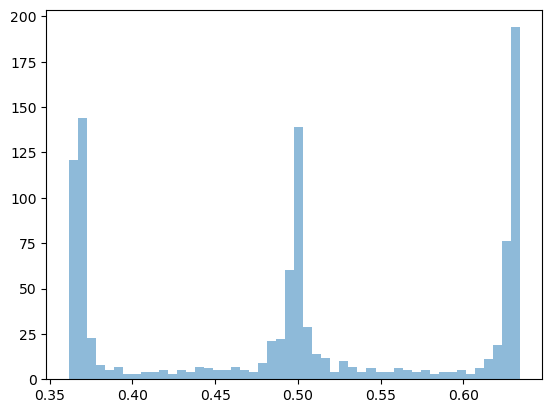

In [6]:
plt.hist(np.sort(softmax_scores[filter_for_low_raw_scores,0]), bins=50, alpha=0.5, label='Partition 1')

(array([194.,  76.,  19.,  11.,   6.,   3.,   5.,   4.,   4.,   3.,   5.,
          4.,   5.,   6.,   4.,   4.,   6.,   4.,   7.,  10.,   4.,  12.,
         14.,  29., 139.,  60.,  22.,  21.,   9.,   4.,   5.,   7.,   5.,
          5.,   6.,   7.,   4.,   5.,   3.,   5.,   4.,   4.,   3.,   3.,
          7.,   5.,   8.,  23., 144., 121.]),
 array([0.3657791 , 0.37123238, 0.37668567, 0.38213895, 0.38759224,
        0.39304552, 0.39849881, 0.40395209, 0.40940538, 0.41485866,
        0.42031195, 0.42576523, 0.43121852, 0.4366718 , 0.44212509,
        0.44757837, 0.45303166, 0.45848494, 0.46393823, 0.46939151,
        0.4748448 , 0.48029808, 0.48575136, 0.49120465, 0.49665793,
        0.50211122, 0.5075645 , 0.51301779, 0.51847107, 0.52392436,
        0.52937764, 0.53483093, 0.54028421, 0.5457375 , 0.55119078,
        0.55664407, 0.56209735, 0.56755064, 0.57300392, 0.57845721,
        0.58391049, 0.58936378, 0.59481706, 0.60027035, 0.60572363,
        0.61117692, 0.6166302 , 0.62208349, 0.

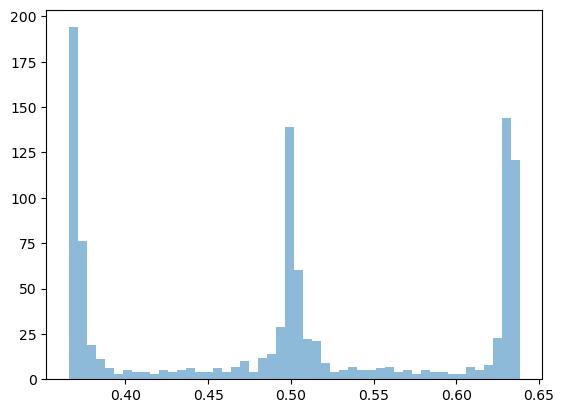

In [7]:
plt.hist(np.sort(softmax_scores[filter_for_low_raw_scores,1]), bins=50, alpha=0.5, label='Partition 2')

In [8]:

knn = 20
part1 = total_variation_scores(0, tc_bunny, tc_total_theta, K=knn)
part2 = total_variation_scores(1, tc_bunny, tc_total_theta, K=knn)

raw_scores = np.column_stack([part1, part2])
softmax_scores = softmax(raw_scores, axis=1)
print(softmax_scores)
CUTOFF = 0.5
thresh = [0.505,0.505]#[np.percentile(softmax_scores[:, i], 50) for i in range(softmax_scores.shape[1])]
LOW_SCORE_CUTOFF = 0.02
filter_for_low_raw_scores = np.linalg.norm(raw_scores, axis=1) > LOW_SCORE_CUTOFF
n_parts = raw_scores.shape[1]

# Landmark-level assignment: confident points by threshold, middle points random.
assigned_part = -np.ones(raw_scores.shape[0], dtype=int)
for i in range(n_parts):
    confident_idx = np.where(
        np.logical_and(softmax_scores[:, i] >= thresh[i], filter_for_low_raw_scores)
    )[0]
    assigned_part[confident_idx] = i

middle_idx = np.where(np.logical_and(assigned_part == -1, filter_for_low_raw_scores))[0]
# rng = np.random.default_rng()
# assigned_part[middle_idx] = rng.integers(0, n_parts, size=middle_idx.size)

# Explicitly ignore low-score points that remain unassigned (-1).
valid_mask = assigned_part != -1
ignored_idx = np.where(~valid_mask)[0]
print(f"Ignored low-score landmarks: {len(ignored_idx)}")

parts = []
weights = []
landmarks = tc_bunny._idx_land
for i in range(n_parts):
    print(f"Partition {i+1}, threshold: {thresh[i]}")
    good_idx = np.where(np.logical_and(assigned_part == i, valid_mask))[0]
    print(f"  confident+random landmarks in partition: {len(good_idx)}")

    if len(good_idx) == 0:
        parts.append(np.array([], dtype=int))
        weights.append(np.array([], dtype=float))
        continue

    good_landmarks = landmarks[good_idx]
    mems_for_good = tc_bunny._dist_land_data[good_idx, :]
    in_cover = mems_for_good < tc_bunny._r_cover            # (n_good, n_data)
    part_pts = np.where(np.any(in_cover, axis=0))[0]
    parts.append(part_pts)

    # Per-data-point weight = max partition-i softmax score over the
    # partition-i landmarks within r_cover of that point. A point that sits
    # near a confident landmark gets ~1.0; a point only reached by ambiguous
    # landmarks gets ~0.5.
    scores_i = softmax_scores[good_idx, i]                  # (n_good,)
    masked = np.where(in_cover[:, part_pts], scores_i[:, None], 0.0)
    weights.append(masked.max(axis=0))

[[0.50061667 0.49938333]
 [0.49996192 0.50003808]
 [0.50036128 0.49963872]
 ...
 [0.5209218  0.4790782 ]
 [0.52048046 0.47951954]
 [0.5205374  0.4794626 ]]
Ignored low-score landmarks: 1220
Partition 1, threshold: 0.505
  confident+random landmarks in partition: 392
Partition 2, threshold: 0.505
  confident+random landmarks in partition: 388


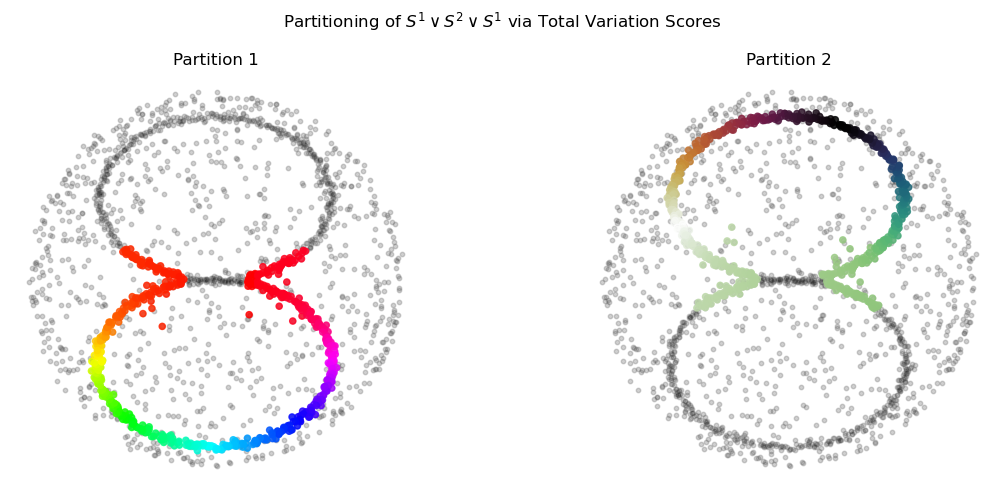

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, ax in enumerate(axes):
    ax.scatter(point_cloud[:, 0], point_cloud[:, 1],
               c='lightgray', s=10, alpha=0.5)
    ax.scatter(point_cloud[tc_bunny._idx_land, 0], point_cloud[tc_bunny._idx_land, 1],
               c='black', s=10, alpha=0.1)
    ax.scatter(point_cloud[parts[i], 0], point_cloud[parts[i], 1],
               c=color_maps[i](tc_total_theta[i][parts[i]] / (2*np.pi)),
               s=20, alpha=0.8)
    ax.set_title(rf'Partition {i + 1}')
    ax.set_aspect('equal')
    ax.axis('off')
fig.suptitle(r'Partitioning of $S^1 \vee S^2 \vee S^1$ via Total Variation Scores')
plt.tight_layout()
plt.show()

In [10]:
Ks = [100, 100]
lams = [5.0, 5.0]
circle_1_fit = TF.fit(
    point_cloud[parts[0], :],
    tc_total_theta[0][parts[0]],
    K=Ks[0],
    lam=lams[0],
    weights=weights[0],
)
circle_2_fit = TF.fit(
    point_cloud[parts[1], :],
    tc_total_theta[1][parts[1]],
    K=Ks[1],
    lam=lams[1],
    weights=weights[1],
)

In [11]:


def assembly(fit, theta,  K, wedge_point_coords, samples=100, wedge_point=np.array([0, 0, 8])):
    if theta is None:
        theta = np.linspace(0, 2*np.pi, num=samples).reshape(-1,1)
    image = TF.Toroidal_Evaluate(fit,theta + wedge_point_coords,K).real
    
    ## Fj(hj(wedge_point))
    offset = wedge_point - TF.Toroidal_Evaluate(fit, wedge_point_coords.reshape(1,-1), K=K).real
    image += offset
    return image

In [12]:
## Find index of wedge point in the initial point cloud
wedge_point = np.array([0, 0, 8])
wedge_idx = np.argmin(np.linalg.norm(point_cloud - wedge_point, axis=1))
wedge_point_coords = tc_total_theta[:, wedge_idx]

In [22]:
theta = np.linspace(0, 2*np.pi, num=100).reshape(-1,1)
res1 = assembly(circle_1_fit, theta, K=Ks[0], wedge_point_coords=wedge_point_coords[0])
res2 = assembly(circle_2_fit, theta, K=Ks[1], wedge_point_coords=wedge_point_coords[1])
fig = go.Figure(data=[ go.Scatter3d(
    x=point_cloud[:,0], y=point_cloud[:,1], z=point_cloud[:,2], 
    mode ='markers', 
    marker=dict(size = 2 , color='gray', opacity=0.3),
    name='Data'),
      go.Scatter3d(
    x=res1[:,0], y=res1[:,1], z=res1[:,2], 
    mode ='lines', 
    line=dict(width = 8 , color=color_maps[0](theta / (2*np.pi))[:,0]),
    name='Circle 1'),
     go.Scatter3d(
    x=res2[:,0]-0.05, y=res2[:,1], z=res2[:,2], 
    mode ='lines', 
    line=dict(width = 8 , color=color_maps[1](theta / (2*np.pi))[:,0]),
    name='Circle 2')
    ])


fig.update_layout(
    width=1200, height=600,
    scene=dict(
        camera=dict(eye=dict(x=0, y=-1, z=3)),
        xaxis=dict(
            showticklabels=False, # Hides the numerical labels
            ticks=""             # Hides the tick marks themselves
        ),
        yaxis=dict(
            showticklabels=False,
            ticks=""
        ),
        zaxis=dict(
            showticklabels=False,
            ticks=""
        )
    ),
    showlegend=True,
    font=dict(size=12)
)


fig.show()

In [73]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# --- 1. Create helper legend handlers ---
class ColorMapHandler:
    """Custom legend handler to draw a colormap bar centered in the handle box."""
    def __init__(self, cmap_name, steps=100, bar_height_frac=0.7, y_shift_frac=0.12):
        self.cmap = plt.colormaps[cmap_name]
        self.steps = steps
        self.bar_height_frac = bar_height_frac
        self.y_shift_frac = y_shift_frac

    def legend_artist(self, legend, orig_handle, fontsize, handlebox):
        x0, y0 = handlebox.xdescent, handlebox.ydescent
        width, height = handlebox.width, handlebox.height

        # Center the color bar, then shift it slightly downward for visual alignment.
        bar_height = self.bar_height_frac * height
        y_bar = y0 + 0.5 * (height - bar_height) - self.y_shift_frac * height

        dx = width / self.steps
        first_rect = None
        for i in range(self.steps):
            color = self.cmap(i / self.steps)
            rect = patches.Rectangle(
                (x0 + i * dx, y_bar), dx, bar_height,
                facecolor=color, edgecolor='none'
            )
            if first_rect is None:
                first_rect = rect
            handlebox.add_artist(rect)
        return first_rect


class TextOnlyHandler:
    """Legend handler that centers custom text and supports vertical shifting."""
    def __init__(self, label, color='black', y_shift_frac=0.0):
        self.label = label
        self.color = color
        self.y_shift_frac = y_shift_frac

    def legend_artist(self, legend, orig_handle, fontsize, handlebox):
        from matplotlib.text import Text

        x0, y0 = handlebox.xdescent, handlebox.ydescent
        width, height = handlebox.width, handlebox.height
        text = Text(
            x=x0 + width / 2,
            y=y0 + height / 2 - self.y_shift_frac * height,
            text=self.label,
            ha='center',
            va='center',
            color=self.color,
            fontsize=fontsize,
        )
        handlebox.add_artist(text)
        return text

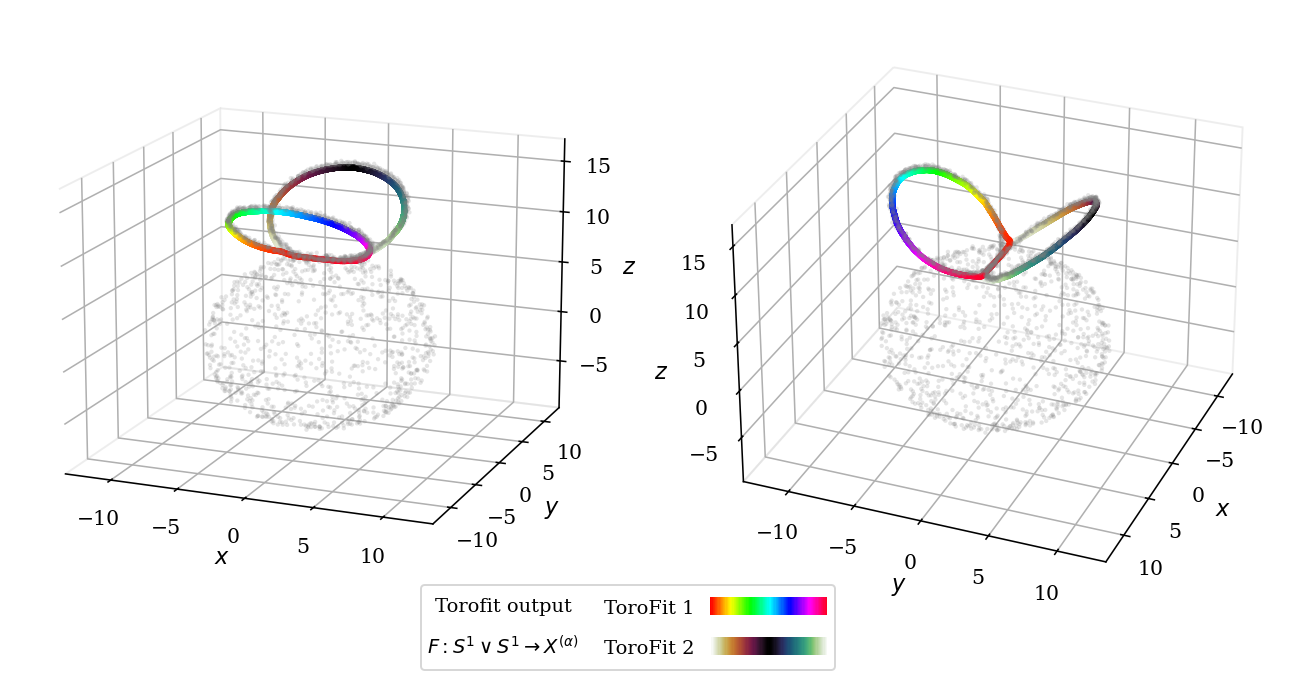

In [76]:
# Publication-ready static visualization of fitted circles on the bunny point cloud.

from pathlib import Path


plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 500,
    "savefig.facecolor": "white",
    "font.family": "DejaVu Serif",
    "font.size": 10.5,
    "axes.labelsize": 11.5,
    "axes.titlesize": 12.5,
    "legend.fontsize": 10,
})

FIGURES_DIR = Path("/Users/tanishqbhatia/Research/tex_drafts/Toroidal_fitting_and_applications/TF_synthetic_plots") 
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def _set_axes_equal(ax):
    # Ensure isotropic 3D scaling so circles are not visually distorted.
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()

    x_range = abs(x_limits[1] - x_limits[0])
    y_range = abs(y_limits[1] - y_limits[0])
    z_range = abs(z_limits[1] - z_limits[0])
    max_range = 0.5 * max([x_range, y_range, z_range])

    x_mid = np.mean(x_limits)
    y_mid = np.mean(y_limits)
    z_mid = np.mean(z_limits)

    ax.set_xlim3d([x_mid - max_range, x_mid + max_range])
    ax.set_ylim3d([y_mid - max_range, y_mid + max_range])
    ax.set_zlim3d([z_mid - max_range, z_mid + max_range])


def _clean_3d_axes(ax):
    ax.grid(False)
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor("#dddddd")
    ax.yaxis.pane.set_edgecolor("#dddddd")
    ax.zaxis.pane.set_edgecolor("#dddddd")


def _plot_theta_colored_line(ax, curve, colors, linewidth=2.2, alpha=0.95):
    # Matplotlib has no direct 3D gradient line primitive, so draw short line segments.
    for j in range(curve.shape[0] - 1):
        ax.plot(
            curve[j:j + 2, 0],
            curve[j:j + 2, 1],
            curve[j:j + 2, 2],
            color=colors[j],
            linewidth=linewidth,
            alpha=alpha,
        )

# ---  Manually Configure the Legend ---
# Proxies for text-only first column and colormap second column.
text_proxy_1 = patches.Rectangle((0, 0), 1, 1, fill=False, edgecolor='none')
text_proxy_2 = patches.Rectangle((0, 0), 1, 1, fill=False, edgecolor='none')
proxy_handle1 = patches.Rectangle((0, 0), 1, 1, fill=False, edgecolor='none')
proxy_handle2 = patches.Rectangle((0, 0), 1, 1, fill=False, edgecolor='none')

# Use your assembly function in this plotting cell to generate both loops.
theta_plot = np.linspace(0, 2 * np.pi, num=1000)
if theta_plot.ndim == 1:
    theta_plot = theta_plot.reshape(-1, 1)

curve1 = assembly(circle_1_fit, theta_plot, K=Ks[0], wedge_point_coords=wedge_point_coords[0])
curve2 = assembly(circle_2_fit, theta_plot, K=Ks[1], wedge_point_coords=wedge_point_coords[1])
curve2[:, 0] = curve2[:, 0] - 0.05

# Use colors defined by theta along both curves.


fig = plt.figure(figsize=(12.2, 5.6), facecolor="white")
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

for ax in [ax1, ax2]:
    ax.set_facecolor("white")
    ax.scatter(
        point_cloud[:, 0],
        point_cloud[:, 1],
        point_cloud[:, 2],
        s=5,
        c="gray",
        alpha=0.2,
        linewidth=0,
        rasterized=True,
    )
    theta_colors = [
        color_maps[0](theta_plot[:, 0] / (2 * np.pi)),
        color_maps[1](theta_plot[:, 0] / (2 * np.pi)),
    ]
    _plot_theta_colored_line(ax, curve2, theta_colors[1], linewidth=3, alpha=0.95)
    _plot_theta_colored_line(ax, curve1, theta_colors[0], linewidth=3, alpha=0.95)

    ax.set_xlabel("$x$", labelpad=2)
    ax.set_ylabel("$y$", labelpad=2)
    ax.set_zlabel("$z$", labelpad=2)
    _set_axes_equal(ax)
    _clean_3d_axes(ax)

# Two complementary viewpoints.
ax1.view_init(elev=16, azim=-68)
ax2.view_init(elev=29, azim=22)

ax1.grid(True, color="#dddddd", linewidth=0.5, alpha=0.8)
ax2.grid(True, color="#dddddd", linewidth=0.5, alpha=0.8)

# 2x2 legend grid: left column text/description, right column ToroFit colormap labels.
fig.legend(
    [text_proxy_1, text_proxy_2, proxy_handle1, proxy_handle2],
    [
        '',
        '',
        'ToroFit 1',
        'ToroFit 2',
    ],
    handler_map={
        text_proxy_1: TextOnlyHandler('Torofit output', y_shift_frac=0.55),
        text_proxy_2: TextOnlyHandler(r'$F: S^1 \vee S^1 \to X^{(\alpha)}$', y_shift_frac=0.55),
        proxy_handle1: ColorMapHandler(color_map_1, bar_height_frac=0.6, y_shift_frac=0.55),
        proxy_handle2: ColorMapHandler(color_map_2, bar_height_frac=0.6, y_shift_frac=0.55),
    },
    loc='lower center',
    bbox_to_anchor=(0.5, 0.03),
    ncol=2,
    columnspacing=2.2,
    handlelength=6,
    handleheight=2,
    markerfirst=False,
    frameon=True,
    alignment='center',
)

# fig.suptitle("Partition-Aware Circular Fits on Bunny Point Cloud", y=0.985, fontsize=15)
fig.subplots_adjust(top=0.88, bottom=0.12, wspace=0.04)

fig.savefig(FIGURES_DIR / "05_bunny_fits.pdf", bbox_inches="tight", pad_inches=0.05)

plt.show()


In [16]:
from ripser import ripser
dgms = ripser(point_cloud, maxdim=2, n_perm=1000)['dgms']

(np.float64(7.842831134796143), np.float64(0.7752257585525513))


/var/folders/f1/jlv6dlps6bd7h3bvmzhcj3_h0000gn/T/ipykernel_14824/1762998877.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


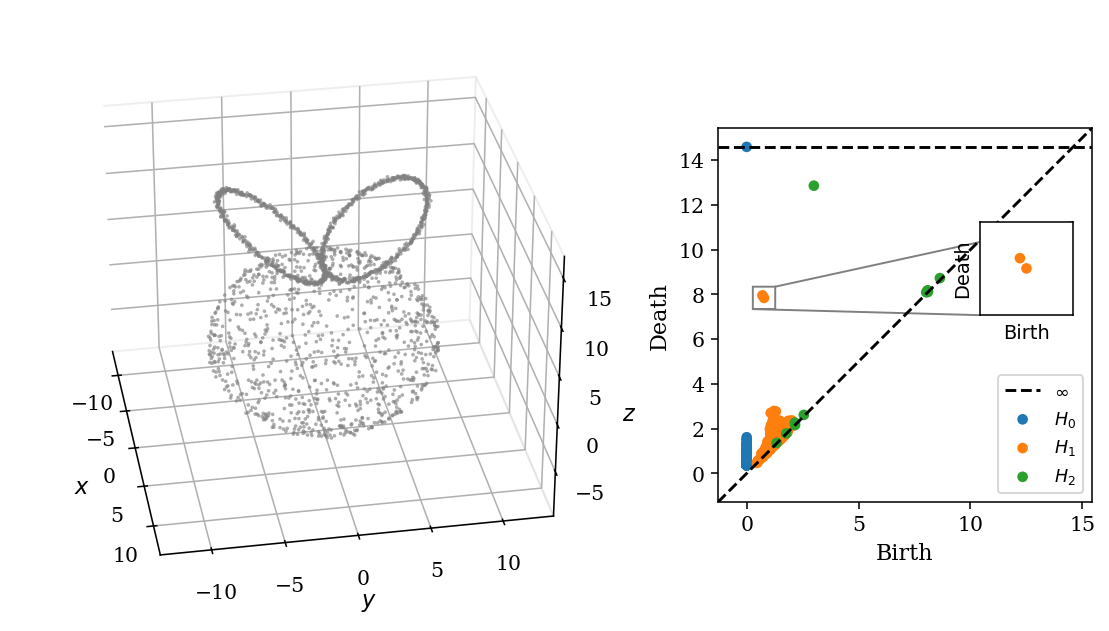

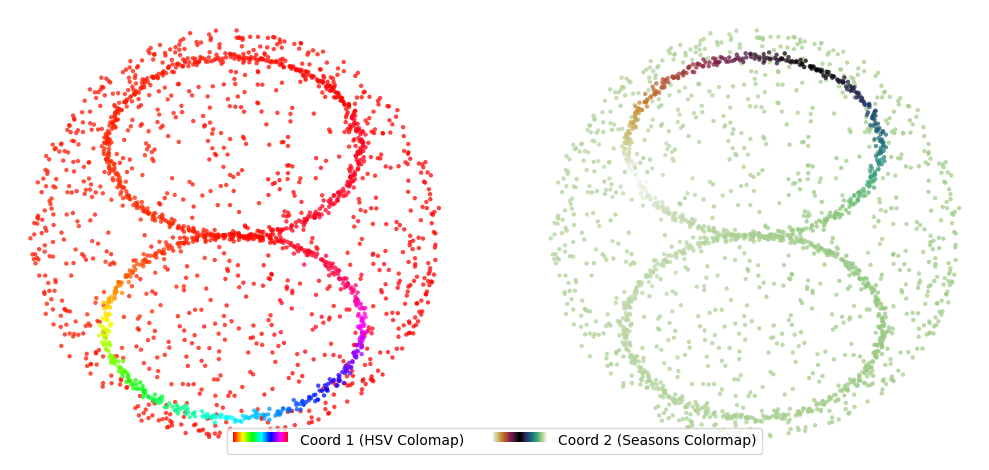

In [77]:
# Publication-ready PDF exports for the draft:
#   - input point cloud (matplotlib companion to the cell-2 plotly view)
#   - toroidal coordinate scatters
#   - persistence diagram of the input cloud
# Reuses FIGURES_DIR and the 3D helpers defined in the cell above.

from persim import plot_diagrams
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(10.6, 5.6), facecolor="white")

# Define a 1x2 grid where the 1st column is 1.5x wider than the 2nd column
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1],  wspace=0.05, hspace=0.05)

# Assign subplots to the grid
ax = fig.add_subplot(gs[0], projection='3d') # 3D Point Cloud
diag_ax = fig.add_subplot(gs[1])             # 2D Persistence Diagram
ax.scatter(
    point_cloud[:, 0],
    point_cloud[:, 1],
    point_cloud[:, 2],
    s=3.5,
    c="gray",
    alpha=0.65,
    linewidth=0,
    rasterized=True,
)
ax.set_xlabel("$x$", labelpad=2)
ax.set_ylabel("$y$", labelpad=2)
ax.set_zlabel("$z$", labelpad=2)
_set_axes_equal(ax)
_clean_3d_axes(ax)
ax.view_init(elev=30, azim=-10) #elev=18, azim=-62
ax.grid(True, color="#dddddd", linewidth=0.5, alpha=0.8)
# ax.set_title(r"Bunny point cloud: $S^{1} \vee S^{2} \vee S^{1}$", pad=8)

plot_diagrams(dgms, ax=diag_ax, size=30)
diag_ax.legend(loc='lower right', frameon=True, fontsize=9)

# Create an inset axis [x_position, y_position, width, height] in normalized coordinates
perm = np.argsort(dgms[1][:,1] - dgms[1][:,0])
target_class = dgms[1][perm[-2:]]; pdist = target_class[:,1] - target_class[:,0]
boxsize = 0.25; boxloc = (target_class[0,1], target_class[0,0])
print(boxloc)
axins = diag_ax.inset_axes([0.7,0.5, boxsize, boxsize])
plot_diagrams(dgms, ax=axins, size=30, legend=False)
axins.set_xticks([])
axins.set_yticks([])
# Zoom in on the specific coordinates of your two close points
x_target, y_target = target_class[0,0], target_class[0,1]  # Example coordinates of the cluster
margin = 0.5
axins.set_xlim(x_target - margin, x_target + margin)
axins.set_ylim(y_target - margin, y_target + margin)

# Draw the connecting lines from the main plot to the zoomed inset
diag_ax.indicate_inset_zoom(axins, edgecolor="black")
# diag_ax.set_title("Persistence diagram of bunny cloud", pad=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_bunny_point_cloud.pdf", bbox_inches="tight", pad_inches=0.05)
plt.show()

# --- Toroidal coordinate scatters (2D x-y projection, colored by each circular coord) ---
fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.8), facecolor="white")
for i, ax in enumerate(axes):
    ax.scatter(
        point_cloud[:, 0],
        point_cloud[:, 1],
        c=color_maps[i](tc_total_theta[i] / (2*np.pi)),
        s=10,
        alpha=0.75,
        linewidth=0,
        rasterized=True,
    )
    ax.set_aspect("equal")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.axis("off")
    ax.set_xlabel('')
    ax.set_ylabel('')
    # ax.set_title(rf"$(\mathrm{{C}}{i + 1})$  $h_{{{i + 1}}}$ on point cloud", pad=6)

# fig.suptitle(r"Toroidal coordinates on $S^{1} \vee S^{2} \vee S^{1}$", y=1.00, fontsize=14)
fig.tight_layout()
fig.legend(
    [proxy_handle1, proxy_handle2],                # The proxy objects
    ['Coord 1 (HSV Colomap)', 'Coord 2 (Seasons Colormap)'], # Your custom labels
    handler_map={
        proxy_handle1: ColorMapHandler(color_map_1),       # Link proxy 1 to hsv symbol
        proxy_handle2: ColorMapHandler(color_map_2)   # Link proxy 2 to twilight symbol
    },
    loc='lower center',       # Place it horizontally at the bottom center
    bbox_to_anchor=(0.5, 0.03), # Pin the exact coordinates relative to the full figure
    ncol=2,                   # Force the two items to sit side-by-side
    handlelength=4,
    handleheight=1.2
)
fig.savefig(FIGURES_DIR / "05_bunny_toroidal_coords.pdf", bbox_inches="tight", pad_inches=0.05)
plt.show()


In [18]:
## Sanity check with cup product table visualization for the bunny cloud.
tc = ToroidalCoords(point_cloud, n_landmarks=len(point_cloud)//3)
tc_theta = tc.get_coordinates(cocycle_idxs=[0,1], perc=0.1)

from torofit.rips_complex_utils import get_nonzero_cup_products_dim_1
cocycle_nonzero_cup_products = get_nonzero_cup_products_dim_1(tc, harmonic_class_idx=[0,1], verbose=True)




Computing rank for coboundary matrix d1 matrix of size (24825, 6554) for Rips complex...


KeyboardInterrupt: 

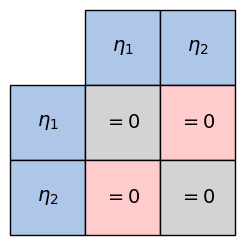

In [ ]:
from torofit.plotting_utils import plot_cup_product_table
fig, ax_table = plot_cup_product_table(cocycle_nonzero_cup_products, harmonic_class_idx=[0,1])
ax_table.set_title("")

fig.savefig(FIGURES_DIR / "05_bunny_cup_product_table.pdf", bbox_inches="tight", pad_inches=0.0)
plt.show()